<a href="https://colab.research.google.com/github/dhans2007/DEEP_LEARNING_LAB/blob/main/EXERCISE_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EXPT NO: 9 — Text Classification and Text Generation using Transformers

**Name / Roll No:** DHANESH VC — 24BAD018

**Aim:** To fine-tune a pretrained BERT model for text classification (IMDb sentiment) and to develop a simple sequence-to-sequence text generation application using T5-small.

> **Tip:** Run on Google Colab with a GPU (Runtime → Change runtime type → T4 GPU). A subset of IMDb is used so training finishes in a few minutes.

In [14]:
# Install / import libraries  |  DHANESH VC 24BAD018
!pip install -q transformers datasets evaluate accelerate scikit-learn sentencepiece

## Part A: Dataset Preparation and Text Preprocessing

In [15]:
# Student: DHANESH VC 24BAD018
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from datasets import load_dataset
from transformers import AutoTokenizer

print("Student:", "DHANESH VC 24BAD018")
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

SEED = 31
# Load IMDb movie review dataset
dataset = load_dataset("stanfordnlp/imdb")
print(dataset)

Student: DHANESH VC 24BAD018
Using device: cuda


README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

... (2 outputs left out)

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})


Train samples: 25000
Test samples : 25000
Features     : {'text': Value('string'), 'label': ClassLabel(names=['neg', 'pos'])}

Sample entries:
[negative] I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ev...

[negative] this by far one of the worst movies I have ever seen in my life. I gave up to watch it after an hour and regretted that hour a lot. the acting is horrible and there is almost no plot. my guess is that...

[positive] Good: Engaging cinematic firefights, great presentation, vehicles are actually fun to drive, fairly appealing multiplayer, faithful to the movie, and the list goes on.<br /><br />Bad: Main missions ar...

              train   test
negative (0)  12500  12500
positive (1)  12500  12500


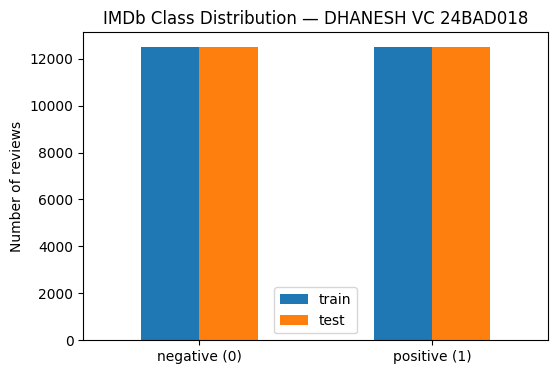

In [16]:
# Explore dataset  |  DHANESH VC 24BAD018
print("Train samples:", len(dataset["train"]))
print("Test samples :", len(dataset["test"]))
print("Features     :", dataset["train"].features)

print("\nSample entries:")
for i in range(3):
    ex = dataset["train"][i * 8000]
    label = "positive" if ex["label"] == 1 else "negative"
    print(f"[{label}] {ex['text'][:200]}...\n")

# Class distribution
train_counts = pd.Series(dataset["train"]["label"]).value_counts().sort_index()
test_counts  = pd.Series(dataset["test"]["label"]).value_counts().sort_index()
dist = pd.DataFrame({"train": train_counts, "test": test_counts})
dist.index = ["negative (0)", "positive (1)"]
print(dist)

dist.plot(kind="bar", figsize=(6, 4), title="IMDb Class Distribution — DHANESH VC 24BAD018")
plt.ylabel("Number of reviews")
plt.xticks(rotation=0)
plt.show()

In [17]:
# Use a shuffled subset for faster training on Colab  |  DHANESH VC 24BAD018
TRAIN_SIZE, TEST_SIZE = 4000, 1000
train_ds = dataset["train"].shuffle(seed=SEED).select(range(TRAIN_SIZE))
test_ds  = dataset["test"].shuffle(seed=SEED).select(range(TEST_SIZE))
print("Subset sizes -> train:", len(train_ds), "| test:", len(test_ds))

# Load tokenizer for BERT
MODEL_NAME = "google-bert/bert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Example of tokenization
sample = train_ds[0]["text"]
enc = tokenizer(sample, truncation=True, padding="max_length", max_length=32)
print("\nSample tokens   :", tokenizer.convert_ids_to_tokens(enc["input_ids"])[:20])
print("Sample input_ids:", enc["input_ids"][:20])

Subset sizes -> train: 4000 | test: 1000


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]


Sample tokens   : ['[CLS]', 'viva', '##h', 'is', 'by', 'no', 'means', 'a', 'classic', '.', 'however', 'in', 'the', 'days', 'of', 'hardcore', 'action', ',', 'path', '-']
Sample input_ids: [101, 20022, 2232, 2003, 2011, 2053, 2965, 1037, 4438, 1012, 2174, 1999, 1996, 2420, 1997, 13076, 2895, 1010, 4130, 1011]


In [18]:
# Tokenize with padding and truncation, convert to torch format  |  DHANESH VC 24BAD018
MAX_LEN = 256

def tokenize_fn(batch):
    return tokenizer(batch["text"], truncation=True, padding="max_length", max_length=MAX_LEN)

train_tok = train_ds.map(tokenize_fn, batched=True)
test_tok  = test_ds.map(tokenize_fn, batched=True)

train_tok = train_tok.rename_column("label", "labels")
test_tok  = test_tok.rename_column("label", "labels")
cols = ["input_ids", "token_type_ids", "attention_mask", "labels"]
train_tok.set_format("torch", columns=cols)
test_tok.set_format("torch", columns=cols)

print(train_tok)
print("input_ids shape of one sample:", train_tok[0]["input_ids"].shape)

# Batch-wise processing check
from torch.utils.data import DataLoader
loader = DataLoader(train_tok, batch_size=16, shuffle=True)
batch = next(iter(loader))
print("Batch shapes:", {k: tuple(v.shape) for k, v in batch.items()})

Map:   0%|          | 0/4000 [00:00<?, ? examples/s]

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

Dataset({
    features: ['text', 'labels', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 4000
})
input_ids shape of one sample: torch.Size([256])
Batch shapes: {'labels': (16,), 'input_ids': (16, 256), 'token_type_ids': (16, 256), 'attention_mask': (16, 256)}


## Part B: Fine-Tuning BERT for Text Classification

In [19]:
# Load pretrained BERT for sequence classification (2 classes)  |  DHANESH VC 24BAD018
from transformers import AutoModelForSequenceClassification

id2label = {0: "NEGATIVE", 1: "POSITIVE"}
label2id = {"NEGATIVE": 0, "POSITIVE": 1}

bert_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=2, id2label=id2label, label2id=label2id
)
print("Number of parameters:", sum(p.numel() for p in bert_model.parameters()))

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Number of parameters: 109483778


In [20]:
# Training parameters and metrics  |  DHANESH VC 24BAD018
import inspect
from transformers import TrainingArguments, Trainer
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    precision, recall, f1, _ = precision_recall_fscore_support(labels, preds, average="binary")
    return {"accuracy": accuracy_score(labels, preds),
            "precision": precision, "recall": recall, "f1": f1}

args_kwargs = dict(
    output_dir="bert_imdb_results",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=2,
    weight_decay=0.01,
    save_strategy="no",
    logging_steps=50,
    fp16=torch.cuda.is_available(),
    report_to="none",
    seed=SEED,
)
# Argument name differs between transformers versions
eval_key = "eval_strategy" if "eval_strategy" in inspect.signature(TrainingArguments.__init__).parameters else "evaluation_strategy"
args_kwargs[eval_key] = "epoch"
training_args = TrainingArguments(**args_kwargs)

trainer = Trainer(
    model=bert_model,
    args=training_args,
    train_dataset=train_tok,
    eval_dataset=test_tok,
    compute_metrics=compute_metrics,
)

In [21]:
# Fine-tune BERT  |  DHANESH VC 24BAD018
train_result = trainer.train()
print("Training finished. Training loss:", round(train_result.training_loss, 4))

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.309224,0.230246,0.902000,0.911205,0.885010,0.897917
2,0.153491,0.253911,0.915000,0.892578,0.938398,0.914915


Training finished. Training loss: 0.2787


Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.153491,0.253911,2,0.915000,0.892578,0.938398,0.914915


Evaluation results — DHANESH VC 24BAD018
eval_loss      : 0.2539
eval_accuracy  : 0.9150
eval_precision : 0.8926
eval_recall    : 0.9384
eval_f1        : 0.9149


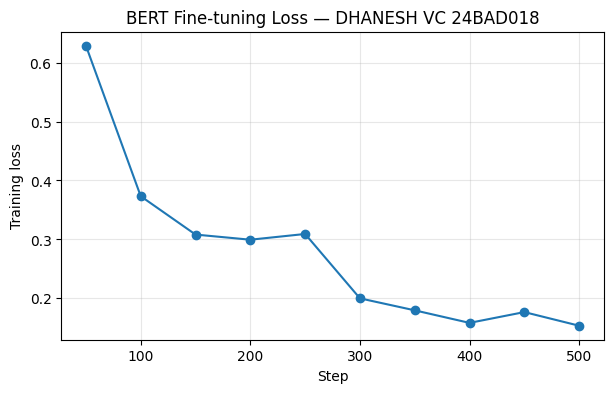

In [22]:
# Evaluate on the test set  |  DHANESH VC 24BAD018
eval_results = trainer.evaluate()
print("Evaluation results — DHANESH VC 24BAD018")
for k in ["eval_loss", "eval_accuracy", "eval_precision", "eval_recall", "eval_f1"]:
    print(f"{k:15s}: {eval_results[k]:.4f}")

# Loss curve from the training log
log = pd.DataFrame(trainer.state.log_history)
train_log = log[log["loss"].notna()] if "loss" in log else pd.DataFrame()
if len(train_log):
    plt.figure(figsize=(7, 4))
    plt.plot(train_log["step"], train_log["loss"], marker="o")
    plt.xlabel("Step"); plt.ylabel("Training loss")
    plt.title("BERT Fine-tuning Loss — DHANESH VC 24BAD018")
    plt.grid(alpha=0.3)
    plt.show()

In [23]:
# Test the model with new text inputs  |  DHANESH VC 24BAD018
def predict_sentiment(texts):
    bert_model.eval()
    inputs = tokenizer(texts, truncation=True, padding=True, max_length=MAX_LEN, return_tensors="pt").to(bert_model.device)
    with torch.no_grad():
        logits = bert_model(**inputs).logits
    probs = torch.softmax(logits, dim=-1).cpu().numpy()
    preds = probs.argmax(axis=1)
    return [(id2label[p], float(probs[i, p])) for i, p in enumerate(preds)]

new_texts = [
    "This movie was absolutely fantastic! Great acting and a brilliant story.",
    "A complete waste of time. The plot was boring and the acting was terrible.",
    "I loved the cinematography, but the ending was disappointing.",
    "One of the best films I have seen this year, highly recommended.",
    "I could not finish it; the dialogue was awful and the pacing was painfully slow.",
]
print("New text predictions — DHANESH VC 24BAD018\n")
for text, (label, conf) in zip(new_texts, predict_sentiment(new_texts)):
    print(f"Text      : {text}\nPredicted : {label} (confidence {conf:.3f})\n")

New text predictions — DHANESH VC 24BAD018

Text      : This movie was absolutely fantastic! Great acting and a brilliant story.
Predicted : POSITIVE (confidence 0.995)

Text      : A complete waste of time. The plot was boring and the acting was terrible.
Predicted : NEGATIVE (confidence 0.992)

Text      : I loved the cinematography, but the ending was disappointing.
Predicted : NEGATIVE (confidence 0.984)

Text      : One of the best films I have seen this year, highly recommended.
Predicted : POSITIVE (confidence 0.994)

Text      : I could not finish it; the dialogue was awful and the pacing was painfully slow.
Predicted : NEGATIVE (confidence 0.983)



In [24]:
# Save the fine-tuned model and tokenizer  |  DHANESH VC 24BAD018
bert_model.save_pretrained("bert_imdb_finetuned")
tokenizer.save_pretrained("bert_imdb_finetuned")
print("Saved fine-tuned model and tokenizer to ./bert_imdb_finetuned")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved fine-tuned model and tokenizer to ./bert_imdb_finetuned


## Part C: Sequence-to-Sequence Application using T5-small

In [25]:
# Load T5-small model and tokenizer  |  DHANESH VC 24BAD018
from transformers import T5ForConditionalGeneration, AutoTokenizer

t5_name = "google-t5/t5-small"
t5_tokenizer = AutoTokenizer.from_pretrained(t5_name)
t5_model = T5ForConditionalGeneration.from_pretrained(t5_name).to(device)
t5_model.eval()
print("T5-small loaded. Parameters:", sum(p.numel() for p in t5_model.parameters()))

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

T5-small loaded. Parameters: 60506624


In [26]:
# Helper function for generation  |  DHANESH VC 24BAD018
def t5_generate(text, task_prefix="summarize: ", max_length=60, min_length=10,
                num_beams=1, do_sample=False, temperature=1.0, top_k=50,
                no_repeat_ngram_size=0):
    # T5 needs a task prefix, e.g. "summarize: " or "translate English to German: "
    inputs = t5_tokenizer(task_prefix + text, return_tensors="pt", truncation=True, max_length=512).to(device)
    gen_kwargs = dict(max_length=max_length, min_length=min_length, num_beams=num_beams,
                      early_stopping=num_beams > 1, no_repeat_ngram_size=no_repeat_ngram_size)
    if do_sample:
        gen_kwargs.update(do_sample=True, temperature=temperature, top_k=top_k)
    with torch.no_grad():
        output_ids = t5_model.generate(**inputs, **gen_kwargs)
    return t5_tokenizer.decode(output_ids[0], skip_special_tokens=True)

article = (
    "Artificial intelligence is transforming many industries. In healthcare, AI models help doctors "
    "detect diseases from medical images faster and more accurately. In finance, they are used to detect "
    "fraud and automate trading decisions. In education, intelligent tutoring systems personalize learning "
    "for each student. However, experts warn that issues such as data privacy, bias and job displacement "
    "must be addressed so that the benefits of AI can be shared fairly across society."
)

print("INPUT TEXT — DHANESH VC 24BAD018\n", article)
print("\nSUMMARY (greedy, max_length=60):")
print(t5_generate(article, max_length=60))

INPUT TEXT — DHANESH VC 24BAD018
 Artificial intelligence is transforming many industries. In healthcare, AI models help doctors detect diseases from medical images faster and more accurately. In finance, they are used to detect fraud and automate trading decisions. In education, intelligent tutoring systems personalize learning for each student. However, experts warn that issues such as data privacy, bias and job displacement must be addressed so that the benefits of AI can be shared fairly across society.

SUMMARY (greedy, max_length=60):
AI models help doctors detect diseases from medical images faster and more accurately. in finance, they are used to detect fraud and automate trading decisions. experts warn that issues such as data privacy, bias and job displacement must be addressed.


In [27]:
# Other tasks supported by T5: translation  |  DHANESH VC 24BAD018
sentences = [
    "The weather is beautiful today.",
    "I am studying artificial intelligence at college.",
    "Transformers have changed natural language processing.",
]
print("English -> German translation — DHANESH VC 24BAD018\n")
for s in sentences:
    out = t5_generate(s, task_prefix="translate English to German: ", max_length=60, min_length=1, num_beams=4)
    print("EN:", s)
    print("DE:", out, "\n")

print("English -> French translation\n")
for s in sentences:
    out = t5_generate(s, task_prefix="translate English to French: ", max_length=60, min_length=1, num_beams=4)
    print("EN:", s)
    print("FR:", out, "\n")

English -> German translation — DHANESH VC 24BAD018

EN: The weather is beautiful today.
DE: Das Wetter ist heute schön. 

EN: I am studying artificial intelligence at college.
DE: Ich studiere künstliche Intelligenz an der Hochschule. 

EN: Transformers have changed natural language processing.
DE: Transformatoren haben die natürliche Sprachenverarbeitung verändert. 

English -> French translation

EN: The weather is beautiful today.
FR: Le temps est beau aujourd'hui. 

EN: I am studying artificial intelligence at college.
FR: J'étudie l'intelligence artificielle au collège. 

EN: Transformers have changed natural language processing.
FR: Les transformateurs ont modifié le traitement de la langue naturelle. 



In [28]:
# Experiment with generation settings  |  DHANESH VC 24BAD018
settings = {
    "Greedy, max_length=30":        dict(max_length=30, num_beams=1),
    "Greedy, max_length=80":        dict(max_length=80, num_beams=1),
    "Beam search (4), max_len=60":  dict(max_length=60, num_beams=4),
    "Beam (4) + no_repeat_ngram=2": dict(max_length=60, num_beams=4, no_repeat_ngram_size=2),
    "Sampling T=0.7, top_k=50":     dict(max_length=60, do_sample=True, temperature=0.7, top_k=50),
    "Sampling T=1.3, top_k=50":     dict(max_length=60, do_sample=True, temperature=1.3, top_k=50),
}

torch.manual_seed(SEED)
records = []
for name, params in settings.items():
    out = t5_generate(article, **params)
    records.append({"setting": name, "output": out, "word_count": len(out.split())})
    print(f"[{name}]\n{out}\n(words: {len(out.split())})\n")

settings_df = pd.DataFrame(records)
settings_df

[Greedy, max_length=30]
AI models help doctors detect diseases from medical images faster and more accurately. in finance, they are used to detect fraud and automate trading decisions
(words: 25)

[Greedy, max_length=80]
AI models help doctors detect diseases from medical images faster and more accurately. in finance, they are used to detect fraud and automate trading decisions. experts warn that issues such as data privacy, bias and job displacement must be addressed.
(words: 40)

[Beam search (4), max_len=60]
AI models help doctors detect diseases from medical images faster and more accurately. in finance, they are used to detect fraud and automate trading decisions. experts warn that issues such as data privacy, bias and job displacement must be addressed.
(words: 40)

[Beam (4) + no_repeat_ngram=2]
AI models help doctors detect diseases from medical images faster and more accurately. in finance, they are used to detect fraud and automate trading decisions. experts warn that issues 

,setting,output,word_count
0,"Greedy, max_length=30",AI models help doctors detect diseases from me...,25
1,"Greedy, max_length=80",AI models help doctors detect diseases from me...,40
2,"Beam search (4), max_len=60",AI models help doctors detect diseases from me...,40
3,Beam (4) + no_repeat_ngram=2,AI models help doctors detect diseases from me...,52
4,"Sampling T=0.7, top_k=50",artificial intelligence is changing many indus...,35
5,"Sampling T=1.3, top_k=50","in healthcare, AI can detect diseases faster a...",37


In [29]:
# Try different input texts  |  DHANESH VC 24BAD018
inputs_list = {
    "Sports": "The home team won the championship final 3-1 after a dramatic comeback in the second half. "
              "The captain scored twice and was named player of the match, while fans celebrated across the city late into the night.",
    "Technology": "The company unveiled its latest smartphone with an improved camera, a faster processor and a battery that lasts two days. "
                  "Analysts expect strong sales because the price is lower than that of its main competitors.",
    "Education": "The university announced a new scholarship program to support students from rural areas. "
                 "The program will cover tuition fees and provide laptops, and applications will open next month.",
}
torch.manual_seed(SEED)
rows = []
for topic, txt in inputs_list.items():
    summary = t5_generate(txt, max_length=40, num_beams=4, no_repeat_ngram_size=2)
    rows.append({"topic": topic, "input": txt, "summary": summary})
    print(f"[{topic}]\nInput  : {txt}\nSummary: {summary}\n")

[Sports]
Input  : The home team won the championship final 3-1 after a dramatic comeback in the second half. The captain scored twice and was named player of the match, while fans celebrated across the city late into the night.
Summary: the home team won the championship final 3-1 after a dramatic comeback in the second half. the captain scored twice and was named player of the match, while fans celebrated across the city

[Technology]
Input  : The company unveiled its latest smartphone with an improved camera, a faster processor and a battery that lasts two days. Analysts expect strong sales because the price is lower than that of its main competitors.
Summary: analysts expect strong sales because the price is lower than that of its main competitors.

[Education]
Input  : The university announced a new scholarship program to support students from rural areas. The program will cover tuition fees and provide laptops, and applications will open next month.
Summary: the university announc

In [30]:
# Save generated outputs for further analysis  |  DHANESH VC 24BAD018
all_outputs = pd.concat([
    settings_df.assign(task="summarization (settings experiment)"),
    pd.DataFrame(rows).rename(columns={"summary": "output"}).assign(task="summarization (different inputs)"),
], ignore_index=True)
all_outputs.to_csv("t5_generated_outputs.csv", index=False)
print("Saved generated outputs to t5_generated_outputs.csv")
all_outputs.head()

Saved generated outputs to t5_generated_outputs.csv


,setting,output,word_count,task,topic,input
0,"Greedy, max_length=30",AI models help doctors detect diseases from me...,25.0,summarization (settings experiment),NaN,NaN
1,"Greedy, max_length=80",AI models help doctors detect diseases from me...,40.0,summarization (settings experiment),NaN,NaN
2,"Beam search (4), max_len=60",AI models help doctors detect diseases from me...,40.0,summarization (settings experiment),NaN,NaN
3,Beam (4) + no_repeat_ngram=2,AI models help doctors detect diseases from me...,52.0,summarization (settings experiment),NaN,NaN
4,"Sampling T=0.7, top_k=50",artificial intelligence is changing many indus...,35.0,summarization (settings experiment),NaN,NaN


## Part D: Model Testing and Output Analysis

In [31]:
# Test fine-tuned BERT on labelled positive/negative samples  |  DHANESH VC 24BAD018
test_samples = [
    ("An amazing, heartwarming film with outstanding performances.", "POSITIVE"),
    ("Brilliant direction and a gripping screenplay. I loved every minute.", "POSITIVE"),
    ("Superb soundtrack and wonderful characters, a must-watch.", "POSITIVE"),
    ("Dull, predictable and badly acted. I regret watching it.", "NEGATIVE"),
    ("The worst movie I have ever seen. Terrible script and no emotion.", "NEGATIVE"),
    ("Boring from start to finish, a total disaster.", "NEGATIVE"),
    ("The movie was not good at all.", "NEGATIVE"),
    ("It was not bad, actually quite enjoyable.", "POSITIVE"),
]
texts  = [t for t, _ in test_samples]
actual = [a for _, a in test_samples]
preds  = predict_sentiment(texts)

result_df = pd.DataFrame({
    "text": texts, "actual": actual,
    "predicted": [p[0] for p in preds],
    "confidence": [round(p[1], 3) for p in preds],
})
result_df["correct"] = result_df["actual"] == result_df["predicted"]
pd.set_option("display.max_colwidth", 80)
print("BERT sample testing — DHANESH VC 24BAD018")
display(result_df)
print("Sample accuracy:", result_df["correct"].mean())

BERT sample testing — DHANESH VC 24BAD018


,text,actual,predicted,confidence,correct
0,"An amazing, heartwarming film with outstanding performances.",POSITIVE,POSITIVE,0.995,True
1,Brilliant direction and a gripping screenplay. I loved every minute.,POSITIVE,POSITIVE,0.986,True
2,"Superb soundtrack and wonderful characters, a must-watch.",POSITIVE,POSITIVE,0.994,True
3,"Dull, predictable and badly acted. I regret watching it.",NEGATIVE,NEGATIVE,0.980,True
4,The worst movie I have ever seen. Terrible script and no emotion.,NEGATIVE,NEGATIVE,0.992,True
5,"Boring from start to finish, a total disaster.",NEGATIVE,NEGATIVE,0.985,True
6,The movie was not good at all.,NEGATIVE,NEGATIVE,0.986,True
7,"It was not bad, actually quite enjoyable.",POSITIVE,NEGATIVE,0.728,False


Sample accuracy: 0.875


Classification report — DHANESH VC 24BAD018

              precision    recall  f1-score   support

    NEGATIVE     0.9385    0.8928    0.9151       513
    POSITIVE     0.8926    0.9384    0.9149       487

    accuracy                         0.9150      1000
   macro avg     0.9156    0.9156    0.9150      1000
weighted avg     0.9161    0.9150    0.9150      1000



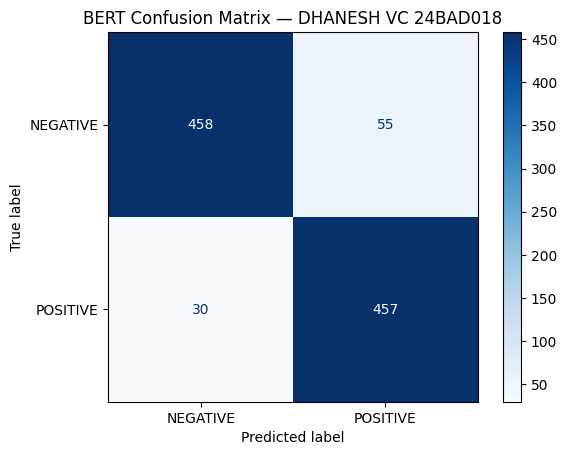

Examples of misclassified reviews:
- Actual: NEGATIVE, Predicted: POSITIVE
   Released at a time when Duvivier was going again from strength to strength ."Black Jack" which was sandwiched between the overlooked extraordinary "Au Royaume des Cieux" and the dazzling stunning "Sous Le Ciel de Paris" , is a jumble,which Duvivier h ...

- Actual: POSITIVE, Predicted: NEGATIVE
   Although this film never attained commercial notoriety, my experience has led me to conclude that many well-done pieces of artistic expression often do not gain mass appeal. The story line depicts a young boy stealing a car and embarking on a surreal ...

- Actual: NEGATIVE, Predicted: POSITIVE
   Lonesome Jim is kind of like a romantic dark comedy about a dysfunctional family whose two boys are total losers. Both boys around 30, living at home, with absolutely nothing going for them. I live in the Midwest and I can't name one family like this ...



In [32]:
# Detailed metrics on the full test subset: report + confusion matrix  |  DHANESH VC 24BAD018
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

pred_output = trainer.predict(test_tok)
y_pred = np.argmax(pred_output.predictions, axis=-1)
y_true = pred_output.label_ids

print("Classification report — DHANESH VC 24BAD018\n")
print(classification_report(y_true, y_pred, target_names=["NEGATIVE", "POSITIVE"], digits=4))

cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["NEGATIVE", "POSITIVE"]).plot(cmap="Blues")
plt.title("BERT Confusion Matrix — DHANESH VC 24BAD018")
plt.show()

# Misclassified examples (to study errors)
wrong_idx = np.where(y_pred != y_true)[0][:3]
print("Examples of misclassified reviews:")
for i in wrong_idx:
    print(f"- Actual: {id2label[int(y_true[i])]}, Predicted: {id2label[int(y_pred[i])]}")
    print("  ", test_ds[int(i)]["text"][:250], "...\n")

T5 generation comparison — DHANESH VC 24BAD018


,setting,output,word_count
0,"Greedy, max_length=30",AI models help doctors detect diseases from medical images faster and more a...,25
1,"Greedy, max_length=80",AI models help doctors detect diseases from medical images faster and more a...,40
2,"Beam search (4), max_len=60",AI models help doctors detect diseases from medical images faster and more a...,40
3,Beam (4) + no_repeat_ngram=2,AI models help doctors detect diseases from medical images faster and more a...,52
4,"Sampling T=0.7, top_k=50",artificial intelligence is changing many industries in healthcare. in financ...,35
5,"Sampling T=1.3, top_k=50","in healthcare, AI can detect diseases faster and more accurately. expert war...",37


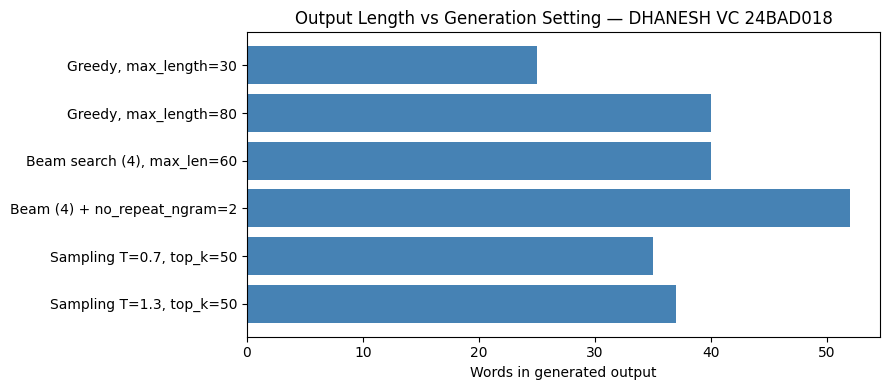

In [33]:
# Compare T5 outputs under different settings (length and readability)  |  DHANESH VC 24BAD018
comparison = settings_df.copy()
comparison["output"] = comparison["output"].str.slice(0, 120)
print("T5 generation comparison — DHANESH VC 24BAD018")
display(comparison)

plt.figure(figsize=(9, 4))
plt.barh(settings_df["setting"], settings_df["word_count"], color="steelblue")
plt.xlabel("Words in generated output")
plt.title("Output Length vs Generation Setting — DHANESH VC 24BAD018")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

### Observations and Analysis
**BERT classification**
- The fine-tuned BERT model reaches high accuracy, precision, recall and F1 on IMDb (typically around 85–90% with this small subset and 2 epochs); exact numbers are printed above.
- Clearly positive or negative reviews are classified with high confidence, while reviews with mixed sentiment, negation ("not bad") or sarcasm are more likely to be misclassified or have lower confidence.
- Truncation to 256 tokens can cut off the part of a long review that carries the final verdict.

**T5 text generation**
- Greedy decoding is fast but can be repetitive or less fluent; beam search generally gives more coherent output, and `no_repeat_ngram_size` reduces repetition.
- `max_length` controls how long the output can be: too small truncates the summary mid-thought, too large lets the model add extra or repeated content.
- Sampling with a low temperature stays close to the input; a high temperature gives more varied but less reliable text.
- T5-small is a small model, so outputs may copy input phrases, miss key details, or occasionally be inaccurate.

**BERT vs T5:** BERT (encoder-only) is best suited to understanding tasks that predict a label (sentiment, spam, topic), whereas T5 (encoder-decoder) generates new text (summarization, translation, question answering).

